# Fase 3 CRISP-DM: Preparación de los Datos y Extracción de Características
**Proyecto Final — Algoritmos y Programación III (Semestre 2026-2)**  
**Universidad Icesi — Departamento de Computación y Sistemas Inteligentes**

---

## 1. Objetivos de la Fase 3 (Basados en los Hallazgos del EDA)

A partir de los resultados de la Fase 2 (`01_EDA_Comprension_Datos.ipynb`), ejecutamos cinco transformaciones rigurosas para preparar los datos antes del modelado:

1. **Balanceo Estratificado (`Pomegranate_Good`):** Reducción aleatoria reproducible de `Pomegranate_Good` ($5,940 \rightarrow 1,150$ imágenes) para corregir el desbalance severo ($IR = 5.47\times \rightarrow 1.12\times$).
2. **Segmentación Multi-Instancia en `Mixed Qualit_Fruits`:** Extracción automática de ejemplares individuales mediante análisis de componentes conexas sobre el mapa de saliencia HSV/Otsu, convirtiendo fotos con múltiples frutas en recortes individuales para conformar la **3.ª categoría de calidad (`Mixed / Regular`)**.
3. **Integración de Recolección Propia:** Lectura automática de `data/custom_group_photos/annotations_template.csv` (cuando existan fotos reales del grupo) bajo el mismo pipeline.
4. **Estandarización y Extracción del Vector de Características $\phi(I) \in \mathbb{R}^{31}$:** Redimensionamiento uniforme a $128 \times 128$ px y cálculo de descriptores morfométricos ($d_{\text{norm}}$, área, *bounding box*), colorimétricos (RGB/HSV + histograma de matiz), textura (Laplaciano, Sobel) y proporción de píxeles oscuros/necróticos.
5. **Partición sin Fuga de Datos (*Zero Data Leakage*):** División estratificada `Train (70%) / Validation (15%) / Test (15%)`. Tanto los terciles de tamaño (`Small`, `Medium`, `Large`) como el escalador `StandardScaler` ($z = (x - \mu_{\text{train}})/\sigma_{\text{train}}$) se ajustan **exclusivamente sobre `Train`**.

In [1]:
from pathlib import Path
import json
import math
import time
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'figure.dpi': 120
})
QUALITY_PALETTE = {'Good': '#2ca02c', 'Mixed': '#ff7f0e', 'Bad': '#d62728'}

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS_DIR = REPO_ROOT / 'experiments' / 'results'
PREP_FIG_DIR = RESULTS_DIR / 'prep_figures'
CHECKPOINTS_DIR = REPO_ROOT / 'experiments' / 'checkpoints'
MIXED_CROPS_DIR = REPO_ROOT / 'data' / 'processed' / 'mixed_crops'

for d in [PREP_FIG_DIR, CHECKPOINTS_DIR, MIXED_CROPS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET_SIZE = (128, 128)

df_inv = pd.read_csv(RESULTS_DIR / 'dataset_inventory.csv')
print(f'Inventario cargado desde Fase 2: {len(df_inv):,} imágenes')

Inventario cargado desde Fase 2: 19,526 imágenes


---
## 2. Balanceo Estratificado de `Pomegranate_Good`

Aplicamos submuestreo aleatorio reproducible (`random_state=42`) sobre `Pomegranate_Good` fijando un tope máximo de **$N_{\text{max}} = 1,150$** imágenes por subclase `Good`/`Bad`, igualando el tamaño típico del resto de frutas (~1,085–1,216 imágenes).

In [2]:
MAX_PER_CLASS = 1150

df_gb = df_inv[df_inv['quality'].isin(['Good', 'Bad'])].copy()
balanced_parts = []
for cls_name, grp in df_gb.groupby('class_combined'):
    if len(grp) > MAX_PER_CLASS:
        balanced_parts.append(grp.sample(n=MAX_PER_CLASS, random_state=RANDOM_STATE))
    else:
        balanced_parts.append(grp)

df_gb_balanced = pd.concat(balanced_parts, ignore_index=True)

counts_before = df_gb['class_combined'].value_counts()
counts_after = df_gb_balanced['class_combined'].value_counts()
print(f'Good/Bad antes del balanceo  : {len(df_gb):,} imgs | IR = {counts_before.max()/counts_before.min():.2f}x')
print(f'Good/Bad después del balanceo: {len(df_gb_balanced):,} imgs | IR = {counts_after.max()/counts_after.min():.2f}x')

Good/Bad antes del balanceo  : 18,452 imgs | IR = 5.47x
Good/Bad después del balanceo: 13,548 imgs | IR = 1.06x


---
## 3. Segmentación Multi-Instancia en `Mixed Qualit_Fruits`

Tal como exige la Sección 2.1 del enunciado, las imágenes de `Mixed Qualit_Fruits` contienen múltiples frutas en una sola fotografía. Implementamos un segmentador multi-instancia basado en:
1. Conversión a espacio HSV y cálculo de un mapa de saliencia cromática (priorizando alta saturación $S$ y contraste frente al fondo).
2. Umbralización adaptativa de Otsu + apertura morfológica para separar frutas que se rozan.
3. Etiquetado de componentes conexas (`ndimage.label`), filtrando regiones con área entre el $1.5\%$ y $65\%$ de la imagen y relación de aspecto razonable, para extraer recortes individuales con un margen del $12\%$.

In [3]:
def otsu_threshold(gray_values: np.ndarray) -> float:
    hist, bin_edges = np.histogram(gray_values.ravel(), bins=256, range=(0.0, 1.0))
    hist = hist.astype(np.float64)
    total = hist.sum()
    if total == 0:
        return 0.5
    prob = hist / total
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    w0 = np.cumsum(prob)
    w1 = 1.0 - w0
    mu = np.cumsum(prob * bin_centers)
    valid = (w0 > 1e-6) & (w1 > 1e-6)
    sigma_b_sq = np.zeros_like(w0)
    sigma_b_sq[valid] = ((mu[-1] * w0[valid] - mu[valid]) ** 2) / (w0[valid] * w1[valid])
    return float(bin_centers[int(np.argmax(sigma_b_sq))])


def rgb_to_hsv_array(rgb_norm: np.ndarray) -> np.ndarray:
    r, g, b = rgb_norm[..., 0], rgb_norm[..., 1], rgb_norm[..., 2]
    maxc = np.maximum(np.maximum(r, g), b)
    minc = np.minimum(np.minimum(r, g), b)
    v = maxc
    deltac = maxc - minc
    s = np.where(maxc > 1e-6, deltac / np.maximum(maxc, 1e-6), 0.0)
    h = np.zeros_like(maxc)
    mask = deltac > 1e-6
    rc = np.where(mask, (maxc - r) / np.maximum(deltac, 1e-6), 0.0)
    gc = np.where(mask, (maxc - g) / np.maximum(deltac, 1e-6), 0.0)
    bc = np.where(mask, (maxc - b) / np.maximum(deltac, 1e-6), 0.0)
    cond_r = mask & (r == maxc)
    cond_g = mask & (g == maxc) & ~cond_r
    cond_b = mask & ~cond_r & ~cond_g
    h[cond_r] = bc[cond_r] - gc[cond_r]
    h[cond_g] = 2.0 + rc[cond_g] - bc[cond_g]
    h[cond_b] = 4.0 + gc[cond_b] - rc[cond_b]
    h = (h / 6.0) % 1.0
    return np.stack([h, s, v], axis=-1)


def extract_individual_crops_from_mixed(image_path: str, max_crops: int = 6) -> list:
    """Detecta y recorta ejemplares individuales presentes en una foto de Mixed Qualit_Fruits."""
    with Image.open(image_path) as img:
        img_rgb = img.convert('RGB')
        w, h = img_rgb.size
        rgb_arr = np.asarray(img_rgb, dtype=np.float32) / 255.0

    hsv = rgb_to_hsv_array(rgb_arr)
    border_px = max(3, min(h, w) // 20)
    border_samples = np.concatenate([
        rgb_arr[:border_px, :, :].reshape(-1, 3),
        rgb_arr[-border_px:, :, :].reshape(-1, 3),
        rgb_arr[:, :border_px, :].reshape(-1, 3),
        rgb_arr[:, -border_px:, :].reshape(-1, 3),
    ], axis=0)
    bg_rgb = np.median(border_samples, axis=0)
    color_dist = np.linalg.norm(rgb_arr - bg_rgb[None, None, :], axis=-1) / math.sqrt(3.0)

    # Saliencia combinando contraste con fondo y saturación cromática
    salience = np.clip(0.55 * color_dist + 0.45 * hsv[..., 1], 0.0, 1.0)
    thresh = otsu_threshold(salience)
    mask = salience > max(thresh, 0.18)
    mask = ndimage.binary_opening(mask, structure=np.ones((5, 5)))
    mask = ndimage.binary_fill_holes(mask)

    labeled, num_features = ndimage.label(mask)
    img_area = float(h * w)
    crops = []
    slices = ndimage.find_objects(labeled)

    for idx, slc in enumerate(slices, start=1):
        if slc is None:
            continue
        comp_area = float((labeled[slc] == idx).sum())
        area_frac = comp_area / img_area
        if not (0.018 <= area_frac <= 0.65):
            continue
        y0, y1 = slc[0].start, slc[0].stop
        x0, x1 = slc[1].start, slc[1].stop
        bh, bw = y1 - y0, x1 - x0
        if min(bh, bw) < 24:
            continue
        # Margen del 12% alrededor de la fruta
        pad_y, pad_x = int(0.12 * bh), int(0.12 * bw)
        cy0, cy1 = max(0, y0 - pad_y), min(h, y1 + pad_y)
        cx0, cx1 = max(0, x0 - pad_x), min(w, x1 + pad_x)
        crop_img = img_rgb.crop((cx0, cy0, cx1, cy1))
        crops.append({'bbox': (cx0, cy0, cx1, cy1), 'image': crop_img})
        if len(crops) >= max_crops:
            break

    # Si no se detectaron múltiples objetos separados, usar recorte central de la imagen
    if len(crops) == 0:
        crops.append({'bbox': (0, 0, w, h), 'image': img_rgb})
    return crops

In [4]:
# Ejecutar la segmentación sobre las 1,074 imágenes de Mixed Qualit_Fruits y guardar recortes
df_mixed = df_inv[df_inv['quality'] == 'Mixed'].copy()
mixed_records = []
demo_examples = []

t0 = time.time()
for row in df_mixed.itertuples(index=False):
    crops = extract_individual_crops_from_mixed(row.filepath, max_crops=5)
    fruit_dir = MIXED_CROPS_DIR / row.fruit
    fruit_dir.mkdir(parents=True, exist_ok=True)
    stem = Path(row.filename).stem

    if len(crops) >= 2 and len(demo_examples) < 3 and row.fruit in {'Apple', 'Orange', 'Banana'}:
        if all(d['fruit'] != row.fruit for d in demo_examples):
            demo_examples.append({'filepath': row.filepath, 'fruit': row.fruit, 'crops': crops})

    for k, c in enumerate(crops):
        crop_path = fruit_dir / f'{stem}_crop_{k}.jpg'
        c['image'].save(crop_path, quality=92)
        mixed_records.append({
            'filepath': str(crop_path),
            'filename': crop_path.name,
            'source_folder': 'Mixed_Cropped',
            'subfolder': row.subfolder,
            'fruit': row.fruit,
            'quality': 'Mixed',
            'class_combined': f'{row.fruit}_Mixed',
            'file_size_kb': round(crop_path.stat().st_size / 1024.0, 2)
        })

df_mixed_crops = pd.DataFrame(mixed_records)
print(f'Imágenes Mixed originales: {len(df_mixed):,} -> Ejemplares individuales recortados: {len(df_mixed_crops):,} ({time.time()-t0:.1f}s)')
print(df_mixed_crops['fruit'].value_counts())

Imágenes Mixed originales: 1,074 -> Ejemplares individuales recortados: 2,130 (45.7s)
fruit
Banana         511
Lime           499
Apple          298
Orange         278
Pomegranate    278
Guava          266
Name: count, dtype: int64


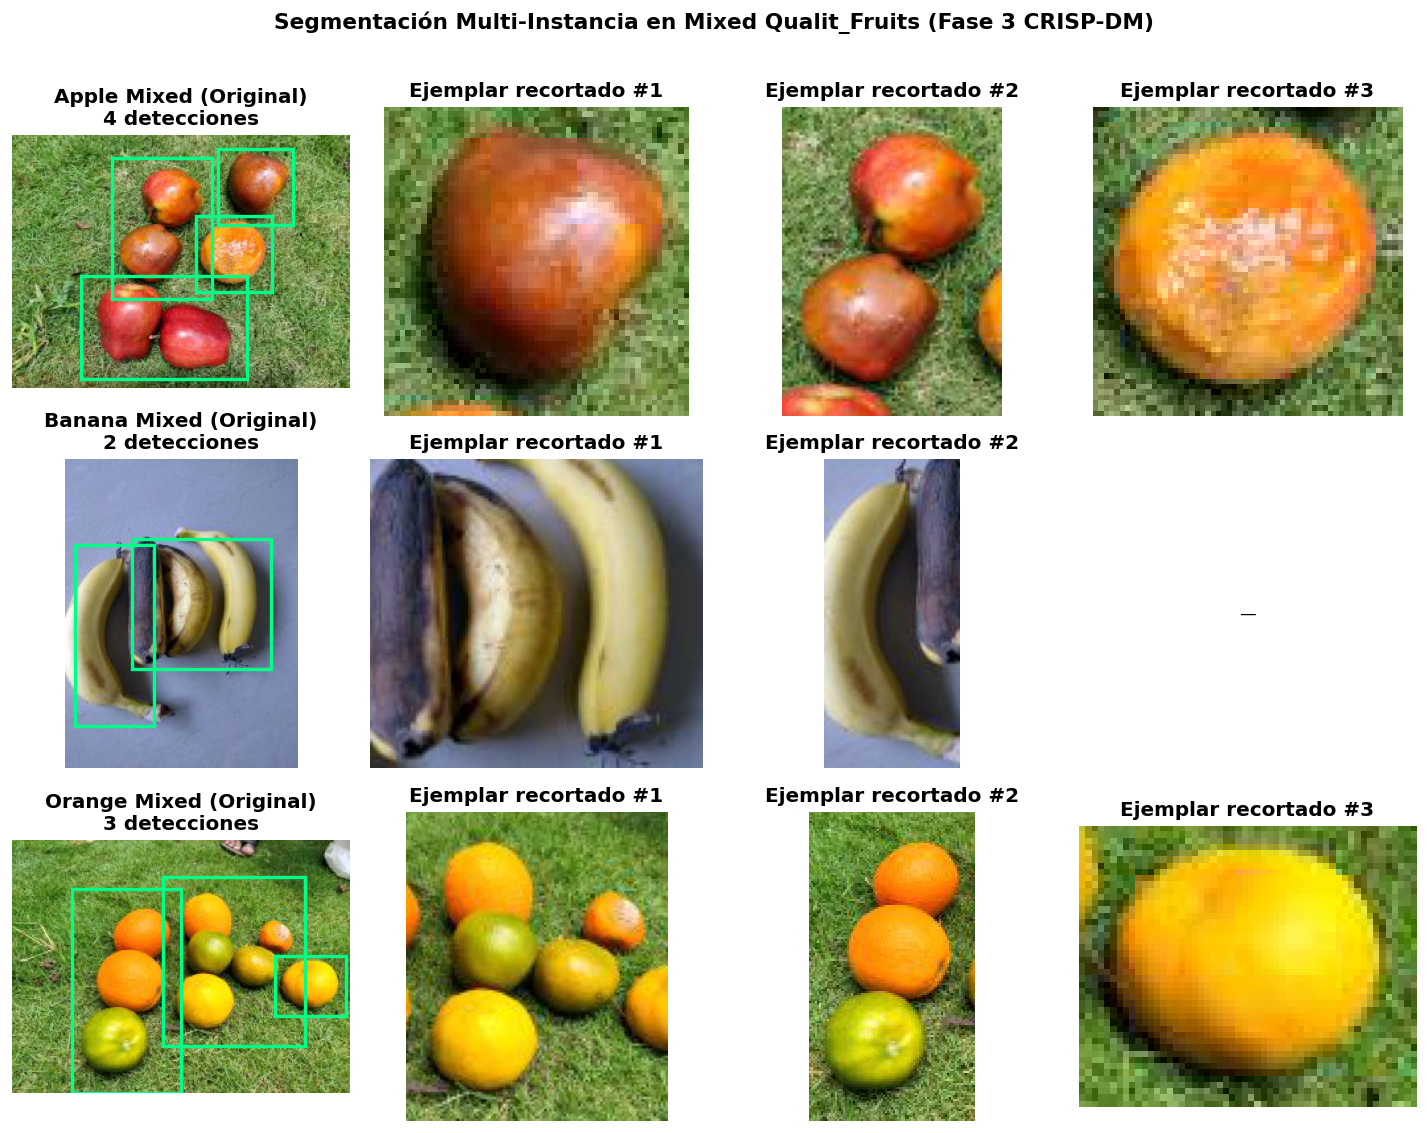

In [5]:
# Gráfica: Demostración visual de recortes individuales extraídos de Mixed Qualit_Fruits
if len(demo_examples) > 0:
    fig, axes = plt.subplots(len(demo_examples), 4, figsize=(12, 3.1 * len(demo_examples)))
    if len(demo_examples) == 1:
        axes = np.expand_dims(axes, axis=0)
    for r, ex in enumerate(demo_examples):
        with Image.open(ex['filepath']) as orig:
            axes[r, 0].imshow(orig.convert('RGB'))
        for c in ex['crops']:
            x0, y0, x1, y1 = c['bbox']
            axes[r, 0].add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor='#00ff88', lw=2))
        axes[r, 0].set_title(f"{ex['fruit']} Mixed (Original)\n{len(ex['crops'])} detecciones")
        axes[r, 0].axis('off')

        for j in range(1, 4):
            if j - 1 < len(ex['crops']):
                axes[r, j].imshow(ex['crops'][j-1]['image'])
                axes[r, j].set_title(f'Ejemplar recortado #{j}')
            else:
                axes[r, j].text(0.5, 0.5, '—', ha='center', va='center')
            axes[r, j].axis('off')

    fig.suptitle('Segmentación Multi-Instancia en Mixed Qualit_Fruits (Fase 3 CRISP-DM)', fontsize=13, fontweight='bold', y=1.01)
    fig.tight_layout()
    fig.savefig(PREP_FIG_DIR / '02_mixed_crops_segmentation_demo.pdf', bbox_inches='tight')
    fig.savefig(PREP_FIG_DIR / '02_mixed_crops_segmentation_demo.png', dpi=200, bbox_inches='tight')
    plt.show()

---
## 4. Integración Automática de Fotos Propias del Grupo + Consolidación

Verificamos si existen fotografías reales en `data/custom_group_photos/` registradas en `annotations_template.csv` (descartando las filas de ejemplo `sample_*`). Estas imágenes quedarán etiquetadas con `is_custom_group = True` para ser evaluadas en el conjunto externo de prueba real (Fase 5).

In [6]:
custom_dir = REPO_ROOT / 'data' / 'custom_group_photos'
custom_csv = custom_csv_path = custom_dir / 'annotations_template.csv'
custom_records = []

if custom_csv.exists():
    df_custom_meta = pd.read_csv(custom_csv)
    for row in df_custom_meta.itertuples(index=False):
        img_file = custom_dir / str(row.filename)
        if img_file.exists() and not str(row.filename).startswith('sample_'):
            q_norm = 'Mixed' if str(row.quality_label).strip().lower() in {'medium', 'mixed', 'regular'} else str(row.quality_label).strip().capitalize()
            custom_records.append({
                'filepath': str(img_file),
                'filename': img_file.name,
                'source_folder': 'Custom_Group',
                'subfolder': 'custom_group_photos',
                'fruit': str(row.fruit_type).strip().capitalize(),
                'quality': q_norm,
                'class_combined': f"{str(row.fruit_type).strip().capitalize()}_{q_norm}",
                'file_size_kb': round(img_file.stat().st_size / 1024.0, 2),
                'is_custom_group': True,
                'manual_size_label': str(row.size_label).strip().capitalize()
            })

df_gb_balanced['is_custom_group'] = False
df_gb_balanced['manual_size_label'] = None
df_mixed_crops['is_custom_group'] = False
df_mixed_crops['manual_size_label'] = None

parts_to_concat = [df_gb_balanced, df_mixed_crops]
if custom_records:
    parts_to_concat.append(pd.DataFrame(custom_records))

df_consolidated = pd.concat(parts_to_concat, ignore_index=True)
print(f'Fotos propias reales detectadas: {len(custom_records)}')
print(f'Total consolidado para extracción de características: {len(df_consolidated):,} imágenes')
df_consolidated['quality'].value_counts()

Fotos propias reales detectadas: 0
Total consolidado para extracción de características: 15,678 imágenes


quality
Good     6806
Bad      6742
Mixed    2130
Name: count, dtype: int64

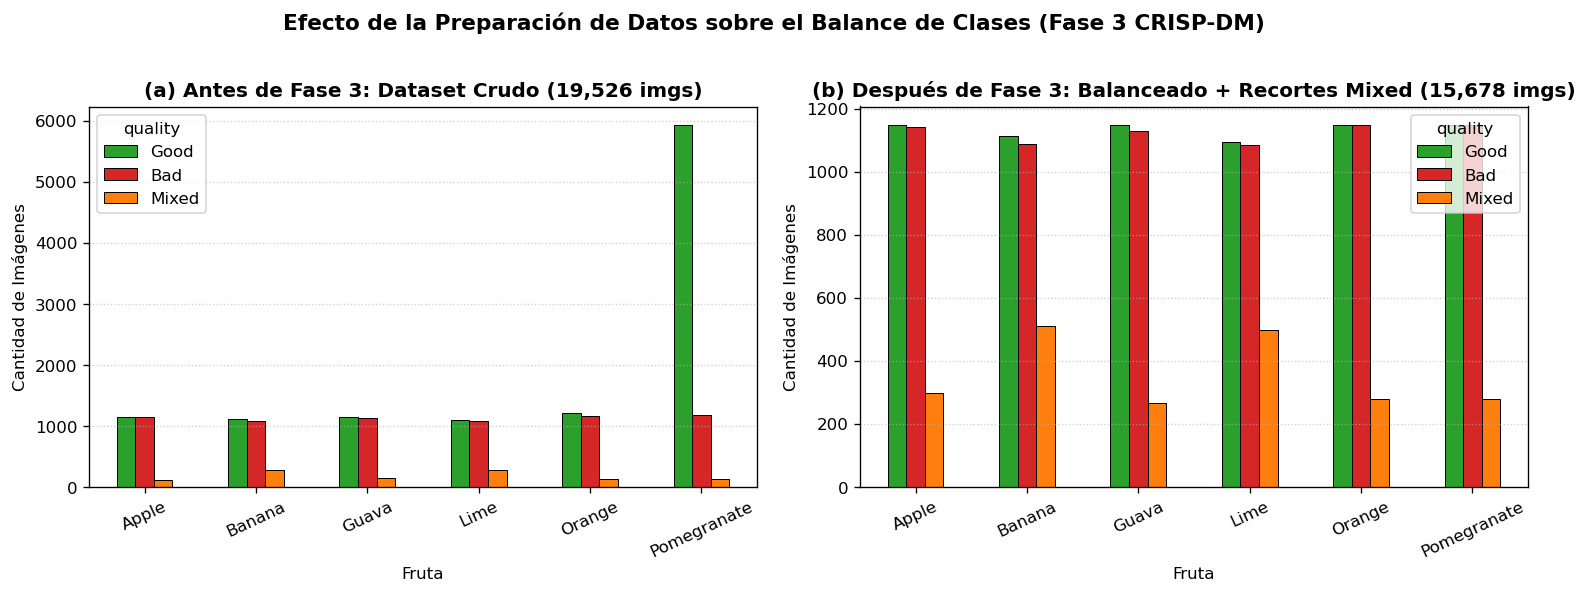

In [7]:
# Gráfica 1 de Fase 3: Comparación Antes vs. Después del Balanceo y Recorte de Mixed
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

before_piv = df_inv.pivot_table(index='fruit', columns='quality', values='filepath', aggfunc='count', fill_value=0)[['Good', 'Bad', 'Mixed']]
after_piv = df_consolidated.pivot_table(index='fruit', columns='quality', values='filepath', aggfunc='count', fill_value=0)[['Good', 'Bad', 'Mixed']]

before_piv.plot(kind='bar', color=[QUALITY_PALETTE[c] for c in before_piv.columns], edgecolor='black', lw=0.6, ax=axes[0])
axes[0].set_title('(a) Antes de Fase 3: Dataset Crudo (19,526 imgs)')
axes[0].set_ylabel('Cantidad de Imágenes')
axes[0].set_xlabel('Fruta')
axes[0].tick_params(axis='x', rotation=25)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

after_piv.plot(kind='bar', color=[QUALITY_PALETTE[c] for c in after_piv.columns], edgecolor='black', lw=0.6, ax=axes[1])
axes[1].set_title(f'(b) Después de Fase 3: Balanceado + Recortes Mixed ({len(df_consolidated):,} imgs)')
axes[1].set_ylabel('Cantidad de Imágenes')
axes[1].set_xlabel('Fruta')
axes[1].tick_params(axis='x', rotation=25)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

fig.suptitle('Efecto de la Preparación de Datos sobre el Balance de Clases (Fase 3 CRISP-DM)', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(PREP_FIG_DIR / '01_balanced_class_distribution.pdf', bbox_inches='tight')
fig.savefig(PREP_FIG_DIR / '01_balanced_class_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

---
## 5. Estandarización a $128 \times 128$ px y Extracción Vectorial $\phi(I) \in \mathbb{R}^{31}$

Para cada imagen $I$ redimensionada a $128 \times 128 \times 3$, calculamos sobre la máscara segmentada $M(u,v)=1$:
- **Morfometría (5):** `area_ratio`, `d_norm`, `bbox_width_norm`, `bbox_height_norm`, `bbox_aspect_ratio`.
- **Momentos de color RGB y HSV (12):** medias y desviaciones estándar $(\mu_R, \mu_G, \mu_B, \sigma_R, \sigma_G, \sigma_B, \mu_H, \mu_S, \mu_V, \sigma_H, \sigma_S, \sigma_V)$.
- **Histograma normalizado de Matiz $H$ (8 bins):** distribución cromática fina para separar tonalidades verdes, amarillas, naranjas, rojas y marrones.
- **Textura y Defectos Superficiales (6):**
  - Varianza y media absoluta del operador Laplaciano $\nabla^2 I_{\text{gray}}$.
  - Magnitud media y desviación del gradiente de Sobel $\|\nabla I_{\text{gray}}\|_2$.
  - Fracción de píxeles oscuros ($V < 0.25$) y de baja saturación oscura ($V < 0.35 \land S < 0.40$), indicadores directos de manchas necróticas y podredumbre.

In [8]:
def segment_foreground_fast(rgb_norm: np.ndarray) -> np.ndarray:
    h, w, _ = rgb_norm.shape
    hsv = rgb_to_hsv_array(rgb_norm)
    b_px = max(2, min(h, w) // 25)
    border = np.concatenate([
        rgb_norm[:b_px, :, :].reshape(-1, 3),
        rgb_norm[-b_px:, :, :].reshape(-1, 3),
        rgb_norm[:, :b_px, :].reshape(-1, 3),
        rgb_norm[:, -b_px:, :].reshape(-1, 3),
    ], axis=0)
    bg_rgb = np.median(border, axis=0)
    color_dist = np.linalg.norm(rgb_norm - bg_rgb[None, None, :], axis=-1) / math.sqrt(3.0)
    salience = np.clip(0.70 * color_dist + 0.30 * hsv[..., 1], 0.0, 1.0)
    thresh = otsu_threshold(salience)
    mask = salience > max(thresh, 0.12)
    mask = ndimage.binary_closing(mask, structure=np.ones((3, 3)))
    mask = ndimage.binary_fill_holes(mask)
    labeled, num_feat = ndimage.label(mask)
    if num_feat > 1:
        sizes = ndimage.sum(mask, labeled, range(1, num_feat + 1))
        mask = labeled == (int(np.argmax(sizes)) + 1)
    if mask.sum() < 0.02 * (h * w):
        yy, xx = np.ogrid[:h, :w]
        mask = ((yy - h / 2.0) ** 2 + (xx - w / 2.0) ** 2) <= (min(h, w) * 0.35) ** 2
    return mask, hsv


def extract_full_feature_vector(image_path: str) -> dict:
    with Image.open(image_path) as img:
        img_resized = img.convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR)
        rgb_arr = np.asarray(img_resized, dtype=np.float32) / 255.0

    h, w, _ = rgb_arr.shape
    mask, hsv_arr = segment_foreground_fast(rgb_arr)
    total_px = float(h * w)
    fruit_px = float(mask.sum())
    area_ratio = fruit_px / total_px
    d_norm = math.sqrt((4.0 * fruit_px) / (math.pi * total_px))

    ys, xs = np.where(mask)
    bbox_h = float(ys.max() - ys.min() + 1) / float(h)
    bbox_w = float(xs.max() - xs.min() + 1) / float(w)
    bbox_aspect = bbox_w / max(bbox_h, 1e-6)

    fg_rgb = rgb_arr[mask]
    fg_hsv = hsv_arr[mask]

    # Histograma normalizado de Matiz H (8 bins en [0, 1])
    h_hist, _ = np.histogram(fg_hsv[:, 0], bins=8, range=(0.0, 1.0), density=False)
    h_hist = h_hist.astype(np.float32) / max(float(h_hist.sum()), 1.0)

    # Textura: Laplaciano y gradiente de Sobel en luminancia
    gray = 0.299 * rgb_arr[..., 0] + 0.587 * rgb_arr[..., 1] + 0.114 * rgb_arr[..., 2]
    lap = ndimage.laplace(gray)[mask]
    gx = ndimage.sobel(gray, axis=1)
    gy = ndimage.sobel(gray, axis=0)
    grad_mag = np.hypot(gx, gy)[mask]

    # Proporción de píxeles necróticos / oscuros
    dark_ratio = float((fg_hsv[:, 2] < 0.25).mean())
    necrotic_ratio = float(((fg_hsv[:, 2] < 0.35) & (fg_hsv[:, 1] < 0.40)).mean())

    feats = {
        'area_ratio': round(area_ratio, 5),
        'd_norm': round(d_norm, 5),
        'bbox_width_norm': round(bbox_w, 5),
        'bbox_height_norm': round(bbox_h, 5),
        'bbox_aspect_ratio': round(bbox_aspect, 5),
        'mean_R': round(float(fg_rgb[:, 0].mean()), 5),
        'mean_G': round(float(fg_rgb[:, 1].mean()), 5),
        'mean_B': round(float(fg_rgb[:, 2].mean()), 5),
        'std_R': round(float(fg_rgb[:, 0].std()), 5),
        'std_G': round(float(fg_rgb[:, 1].std()), 5),
        'std_B': round(float(fg_rgb[:, 2].std()), 5),
        'mean_H': round(float(fg_hsv[:, 0].mean()), 5),
        'mean_S': round(float(fg_hsv[:, 1].mean()), 5),
        'mean_V': round(float(fg_hsv[:, 2].mean()), 5),
        'std_H': round(float(fg_hsv[:, 0].std()), 5),
        'std_S': round(float(fg_hsv[:, 1].std()), 5),
        'std_V': round(float(fg_hsv[:, 2].std()), 5),
        'laplacian_var': round(float(np.var(lap)), 6),
        'laplacian_abs_mean': round(float(np.abs(lap).mean()), 6),
        'sobel_mean': round(float(grad_mag.mean()), 6),
        'sobel_std': round(float(grad_mag.std()), 6),
        'dark_pixel_ratio': round(dark_ratio, 5),
        'necrotic_pixel_ratio': round(necrotic_ratio, 5),
    }
    for b_idx in range(8):
        feats[f'hue_bin_{b_idx}'] = round(float(h_hist[b_idx]), 5)
    return feats

In [9]:
t0 = time.time()
extracted_rows = []
errors = 0

for row in df_consolidated.itertuples(index=False):
    try:
        feats = extract_full_feature_vector(row.filepath)
        extracted_rows.append({
            'filepath': row.filepath,
            'filename': row.filename,
            'fruit': row.fruit,
            'quality': row.quality,
            'class_combined': row.class_combined,
            'is_custom_group': row.is_custom_group,
            'manual_size_label': row.manual_size_label,
            **feats
        })
    except Exception:
        errors += 1

df_features = pd.DataFrame(extracted_rows)
print(f'Extracción completada en {time.time()-t0:.1f}s | Filas válidas: {len(df_features):,} | Errores: {errors}')
df_features.head()

Extracción completada en 320.6s | Filas válidas: 15,678 | Errores: 0


,filepath,filename,fruit,quality,class_combined,is_custom_group,manual_size_label,area_ratio,d_norm,bbox_width_norm,...,dark_pixel_ratio,necrotic_pixel_ratio,hue_bin_0,hue_bin_1,hue_bin_2,hue_bin_3,hue_bin_4,hue_bin_5,hue_bin_6,hue_bin_7
0,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,IMG20200728175856.jpg,Apple,Bad,Apple_Bad,False,None,0.21161,0.51907,0.59375,...,0.16585,0.05076,0.95472,0.01067,0.0,0.0,0.00000,0.01067,0.00490,0.01904
1,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,IMG20200728175907.jpg,Apple,Bad,Apple_Bad,False,None,0.21753,0.52628,0.60938,...,0.17228,0.05275,0.94893,0.02946,0.0,0.0,0.00056,0.00168,0.00421,0.01515
2,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,IMG20200728175908.jpg,Apple,Bad,Apple_Bad,False,None,0.19983,0.50441,0.58594,...,0.12767,0.02138,0.97404,0.01436,0.0,0.0,0.00000,0.00000,0.00122,0.01038
3,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,IMG20200728175909.jpg,Apple,Bad,Apple_Bad,False,None,0.24194,0.55502,0.63281,...,0.13951,0.03910,0.97301,0.00151,0.0,0.0,0.00000,0.00832,0.00378,0.01337
4,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,IMG20200728175910.jpg,Apple,Bad,Apple_Bad,False,None,0.18170,0.48099,0.55469,...,0.15149,0.01680,0.96607,0.00000,0.0,0.0,0.00034,0.00571,0.00437,0.02351


---
## 6. Partición Estratificada (`Train 70% / Val 15% / Test 15%`), Terciles de Tamaño y Escalamiento Z-Score

Para garantizar **cero fuga de datos (*Zero Data Leakage*)**:
1. Separamos primero las fotos propias (`is_custom_group == True`) como conjunto externo `external_test`.
2. El resto del dataset se divide estratificadamente por `class_combined` en **`train` (70%)**, **`val` (15%)** y **`test` (15%)**.
3. Calculamos los terciles de tamaño $(q_{1/3}, q_{2/3})$ de `d_norm` por fruta **únicamente en `train`** y los aplicamos a todo el dataset.
4. Ajustamos el `StandardScaler` **únicamente en `train`** y lo guardamos en `experiments/checkpoints/feature_scaler.joblib`.

In [10]:
df_kaggle = df_features[~df_features['is_custom_group']].copy()
df_custom = df_features[df_features['is_custom_group']].copy()

# División 70% Train / 30% Temp
idx_train, idx_temp = train_test_split(
    df_kaggle.index,
    test_size=0.30,
    stratify=df_kaggle['class_combined'],
    random_state=RANDOM_STATE
)
# División 15% Val / 15% Test
idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    stratify=df_kaggle.loc[idx_temp, 'class_combined'],
    random_state=RANDOM_STATE
)

df_kaggle.loc[idx_train, 'split'] = 'train'
df_kaggle.loc[idx_val, 'split'] = 'val'
df_kaggle.loc[idx_test, 'split'] = 'test'
if len(df_custom) > 0:
    df_custom['split'] = 'external_test'

df_final = pd.concat([df_kaggle, df_custom], ignore_index=True)

# Umbrales de tamaño (terciles de d_norm) aprendidos SOLO sobre Train
size_thresholds = {}
train_mask = df_final['split'] == 'train'
for fruit_name, grp in df_final[train_mask].groupby('fruit'):
    q1 = float(grp['d_norm'].quantile(1.0 / 3.0))
    q2 = float(grp['d_norm'].quantile(2.0 / 3.0))
    size_thresholds[fruit_name] = {'q33': round(q1, 5), 'q66': round(q2, 5)}

with open(RESULTS_DIR / 'size_thresholds_train.json', 'w', encoding='utf-8') as f:
    json.dump(size_thresholds, f, indent=2)

def apply_size_threshold(row) -> str:
    if pd.notna(row['manual_size_label']):
        return str(row['manual_size_label'])
    th = size_thresholds[row['fruit']]
    if row['d_norm'] < th['q33']:
        return 'Small'
    elif row['d_norm'] < th['q66']:
        return 'Medium'
    return 'Large'

df_final['size_category'] = df_final.apply(apply_size_threshold, axis=1)

# Escalamiento Z-score sobre las 31 features numéricas (fit solo en Train)
feature_cols = [
    'area_ratio', 'd_norm', 'bbox_width_norm', 'bbox_height_norm', 'bbox_aspect_ratio',
    'mean_R', 'mean_G', 'mean_B', 'std_R', 'std_G', 'std_B',
    'mean_H', 'mean_S', 'mean_V', 'std_H', 'std_S', 'std_V',
    'laplacian_var', 'laplacian_abs_mean', 'sobel_mean', 'sobel_std',
    'dark_pixel_ratio', 'necrotic_pixel_ratio'
] + [f'hue_bin_{i}' for i in range(8)]

scaler = StandardScaler()
scaler.fit(df_final.loc[train_mask, feature_cols])
joblib.dump({'scaler': scaler, 'feature_cols': feature_cols}, CHECKPOINTS_DIR / 'feature_scaler.joblib')

df_final.to_csv(RESULTS_DIR / 'prepared_features_dataset.csv', index=False)
print('Distribución final por split y calidad:')
display(pd.crosstab(df_final['split'], df_final['quality'], margins=True))

Distribución final por split y calidad:


quality,Bad,Good,Mixed,All
split,,,,
test,1012,1021,319,2352
train,4719,4764,1491,10974
val,1011,1021,320,2352
All,6742,6806,2130,15678


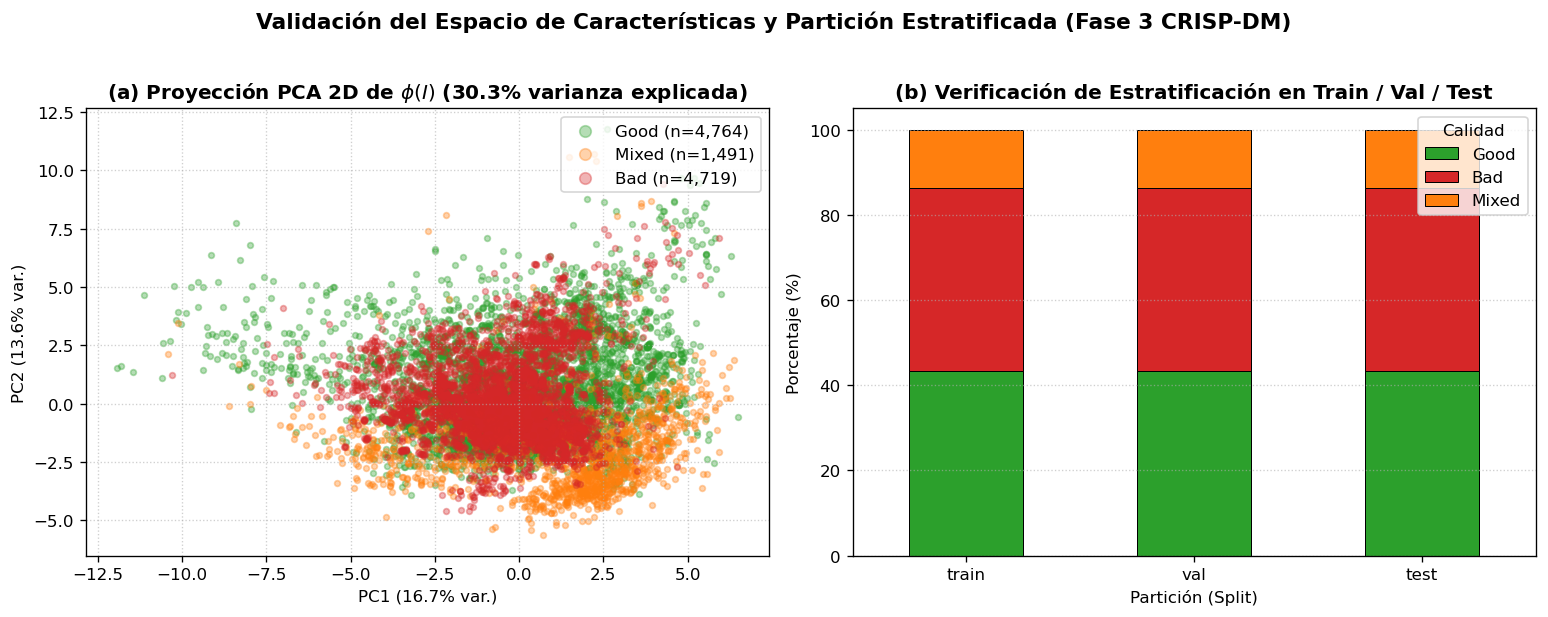

In [11]:
# Gráfica 3: Verificación de estratificación y proyección PCA 2D sobre el espacio escalado de Train
X_train_scaled = scaler.transform(df_final.loc[train_mask, feature_cols])
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train_scaled)
var_exp = pca.explained_variance_ratio_ * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))

# Panel A: Proyección PCA 2D coloreada por Calidad
train_qual = df_final.loc[train_mask, 'quality'].values
for qual in ['Good', 'Mixed', 'Bad']:
    m = train_qual == qual
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], label=f'{qual} (n={m.sum():,})', color=QUALITY_PALETTE[qual], alpha=0.35, s=12)
axes[0].set_title(f'(a) Proyección PCA 2D de $\phi(I)$ ({var_exp[0]+var_exp[1]:.1f}% varianza explicada)')
axes[0].set_xlabel(f'PC1 ({var_exp[0]:.1f}% var.)')
axes[0].set_ylabel(f'PC2 ({var_exp[1]:.1f}% var.)')
axes[0].legend(loc='upper right', markerscale=2)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Proporciones de Calidad en Train / Val / Test
ct_pct = pd.crosstab(df_final['split'], df_final['quality'], normalize='index') * 100.0
ct_pct = ct_pct.reindex(['train', 'val', 'test'])[['Good', 'Bad', 'Mixed']]
ct_pct.plot(kind='bar', stacked=True, color=[QUALITY_PALETTE[c] for c in ct_pct.columns], edgecolor='black', lw=0.6, ax=axes[1])
axes[1].set_title('(b) Verificación de Estratificación en Train / Val / Test')
axes[1].set_ylabel('Porcentaje (%)')
axes[1].set_xlabel('Partición (Split)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Calidad', loc='upper right')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

fig.suptitle('Validación del Espacio de Características y Partición Estratificada (Fase 3 CRISP-DM)', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(PREP_FIG_DIR / '03_pca_and_split_verification.pdf', bbox_inches='tight')
fig.savefig(PREP_FIG_DIR / '03_pca_and_split_verification.png', dpi=200, bbox_inches='tight')
plt.show()